# NLP Group Assignment 2025/26 — Speech Track


**Competition:** Ancient History & Politics (Competition ID: 1) — **Speech Mode**

---

This notebook evaluates the same models from the text notebook on the **speech interface** of the game.
The only new component is a Whisper ASR transcription step that converts spoken questions and options into text.

```
spoken question + 4 spoken options → Whisper ASR → text → prompt builder → LLM → letter A/B/C/D → submit
```
### Video Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing


## 1. Setup

In [ ]:
from google.colab import drive
import sys
import os

drive.mount('/content/gdrive')

PROJECT_DIR = "/content/gdrive/MyDrive/Colab Notebooks/NLP_assignment"
client_package_dir = os.path.join(PROJECT_DIR, "millionaire_client")


SAVE_DIR = os.path.join(PROJECT_DIR, "speech_outputs") + "/"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Project dir:", PROJECT_DIR)
print("Save dir:   ", SAVE_DIR)

Mounted at /content/gdrive
Project dir: /content/gdrive/MyDrive/Colab Notebooks/NLP_assignment
Save dir:    /content/gdrive/MyDrive/Colab Notebooks/NLP_assignment/speech_outputs/


In [ ]:
import shutil
import importlib

source_package_dir = client_package_dir
target_package_dir = "/content/millionaire_client"

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)
shutil.copytree(source_package_dir, target_package_dir)

if "/content" not in sys.path:
    sys.path.insert(0, "/content")
importlib.invalidate_caches()

print("Copied client package to:", target_package_dir)

Copied client package to: /content/millionaire_client


In [ ]:
import subprocess, sys


subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--upgrade",
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "bitsandbytes",
    "sentencepiece",
    "safetensors>=0.5.3",
    "faster-whisper",
    "wikipedia",
])
print("Dependencies installed. Restart the runtime if a core package changed.")

Dependencies installed. Restart the runtime if a core package changed.


In [ ]:
import torch
import re
import time
import json
import gc
import tempfile

import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline, BitsAndBytesConfig
from faster_whisper import WhisperModel

from millionaire_client import (
    MillionaireClient,
    AuthenticationError,
    GameError,
    TimeoutError,
    RateLimitError,
)

print("GPU available:", torch.cuda.is_available())


experiment_log     = []
comparison_results = {}
summary_rows       = []


USE_4BIT = True

GPU available: False


In [ ]:
API_URL = "http://131.175.15.22:51111/"


username = os.environ.get("MILLIONAIRE_USER")
password = os.environ.get("MILLIONAIRE_PASS")
if not username or not password:
    from getpass import getpass
    username = username or input("Millionaire username: ")
    password = password or getpass("Millionaire password: ")

client = MillionaireClient(API_URL)
try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except Exception as e:
    print(f"Login failed: {e}")

Millionaire username: <user>
Millionaire password: ··········
Welcome, <user>! Role: student


In [ ]:
competitions = client.competitions.list_all()
for comp in competitions:
    print(f"ID: {comp.id} | Name: {comp.name} | Questions: {comp.question_count}")

ID: 0 | Name: Entertainment | Questions: 840
ID: 1 | Name: Ancient History and Politics | Questions: 454
ID: 2 | Name: Science and Nature | Questions: 5347
ID: 3 | Name: Maths | Questions: 390
ID: 4 | Name: Philosophy and Psychology | Questions: 3248
ID: 5 | Name: News | Questions: 1860


In [ ]:
comp_id = 1  # History and Ancient Civilizations
COMPETITION_ID = comp_id

## 2. Whisper ASR Front-end

The only new component compared to the text notebook is the Whisper transcription step.
The API serves audio as WAV bytes; we save to a temporary file and transcribe with faster-whisper.
ASR confidence diagnostics (avg log-prob, no-speech prob) are logged for error analysis.

| Component | Detail |
|-----------|--------|
| ASR model | faster-whisper "medium.en"|
| Device | CUDA (float16) / CPU (int8) |
| Input | WAV bytes from game API |
| Output | Transcribed text + confidence diagnostics |

> **Note:** ASR adds ~0.84s overhead per question. All models must answer within the 30-second timeout.


In [ ]:
asr_device = "cuda" if torch.cuda.is_available() else "cpu"
asr_compute_type = "float16" if asr_device == "cuda" else "int8"
CURRENT_ASR_MODEL_NAME = "medium.en"

asr_model = WhisperModel(
    CURRENT_ASR_MODEL_NAME,
    device=asr_device,
    compute_type=asr_compute_type,
)
print("Loaded ASR model:", CURRENT_ASR_MODEL_NAME,
      "| device:", asr_device, "| compute_type:", asr_compute_type)

Loaded ASR model: medium.en | device: cuda | compute_type: float16


In [ ]:
ASR_DOMAIN_PROMPT = (
    # Ancient civilizations
    "Ancient history, ancient Greece, ancient Rome, ancient Egypt, Mesopotamia. "
    "Hittite, Hittite documents, Tawagalawa letter, Ahhiyawa, Achaean, Mycenaean. "
    "Ma'at, pharaoh, dynasty, hieroglyph, Babylonian, Assyrian, Sumerian, cuneiform. "
    # Egyptian specific
    "Eleusinian mysteries, Old Kingdom, Early Dynastic Period, Period of Reunification. "
    "votive inscription, limestone inscription, Early Dynastic II, Horus incarnation. "
    # Roman specific
    "libertus, liberti, freedman, Roman citizen, patrician, plebeian, peregrini. "
    "Julius Caesar, Augustus, Nero, Diocletian, Constantine, Justinian, Hadrian. "
    "Praetorian Guard, Roman senate, consul, praetor, tetrarchy, Milvian Bridge. "
    "cingulum, haruspex, augur, Corpus Juris Civilis, annalistic, monographic. "
    "gladiator, amphitheatre, Colosseum, Roman salute, panem et circenses. "
    "virtus, gravitas, pietas, dignitas, auctoritas, Roman virtue. "
    # Greek specific
    "Socrates, Aristotle, Plato, Homer, Iliad, Odyssey, Acropolis, Parthenon. "
    "ephors, agora, polis, Athens, Sparta, Corinth, Thebes, Macedon. "
    "Eleusinian, Antikythera mechanism, pederastic, eromenos, erastes. "
    "classical antiquity, Hellenistic, Attic Greek, Koine Greek, Mycenaean Greek. "
    "entasis, Doric column, entablature, architectural order, Golden Mean. "
    "xenia, symposium, ostracism, demokratia, oligarchy, tyranny. "
    # Alexander and Persian
    "Alexander the Great, Persian Empire, Achaemenid, Ptolemy, Seleucid. "
    "Iranian upper classes, Macedonian elite, Macedonian burial, proskynesis. "
    # Linguistic terms
    "Tawagalawa, Ahhiyawa, Achaeans, Danaans, Argives, Homeric epithet. "
    "Cappadocian Greeks, Linear B, syllabic characters, vowel shift, Attic-Ionic. "
    # Question patterns
    "Which of the following best describes, What term describes, According to. "
    "What was the primary, What is the fundamental principle, How does. "
    "Which period, What event marked, In Homer's works, In ancient Greek. "
    "What strategy did, Which ancient, What was the significance of. "
)


def transcribe_wav_bytes_with_metadata(audio_bytes):
    """Transcribe WAV bytes with domain prompt and post-correction."""
    start_time = time.time()
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=True) as f:
        f.write(audio_bytes)
        f.flush()
        segments, info = asr_model.transcribe(
            f.name,
            beam_size=5,
            language="en",
            vad_filter=True,
            initial_prompt=ASR_DOMAIN_PROMPT,
        )
        segments = list(segments)

    elapsed = time.time() - start_time
    text = " ".join(seg.text.strip() for seg in segments).strip()

    # Remove leading noise words/phrases
    text = re.sub(
        r"^(hahaha[!,.]?|ho[,.]?\s*ho[,.]?\s*ho[,.]?|oh[,.]?|hakko[,.]?|"
        r"aku[,.]?|rich|out at|glitch of|acha[,.]?|quits of|but )\s+",
        "", text, flags=re.IGNORECASE
    ).strip()

    # Fix common misrecognitions from your actual outputs
    fixes = [
        (r"^glitch\b",                  "Which"),
        (r"\bhitchhike\b",              "Hittite"),
        (r"\bhit site\b",               "Hittite"),
        (r"\bla burtis\b",              "libertus"),
        (r"\bellucinian\b",             "Eleusinian"),
        (r"\bma'al\b",                  "Ma'at"),
        (r"\bmao\b",                    "Ma'at"),
        (r"\baphors\b",                 "ephors"),
        (r"\beifers\b",                 "ephors"),
        (r"\banelistic\b",              "annalistic"),
        (r"\bcorpus jurisavirus\b",     "Corpus Juris Civilis"),
        (r"\bsingulum\b",               "cingulum"),
        (r"\bapollos?\b",               "polis"),
        (r"\b5,065\b",                  "565"),
        (r"\b1,987\b",                  "1987"),
        # New fixes from your outputs
        (r"\bcayons\b",                 "Achaeans"),
        (r"\banalogic theorem\b",       "Antikythera mechanism"),
        (r"\banacic theorem\b",         "Antikythera mechanism"),
        (r"\bparagrini\b",              "peregrini"),
        (r"\bmillvian\b",               "Milvian"),
        (r"\bmilivian\b",               "Milvian"),
        (r"\beifers\b",                 "ephors"),
        (r"\beleusian\b",               "Eleusinian"),
        (r"\btawagalava\b",             "Tawagalawa"),
        (r"\bahiyawa\b",                "Ahhiyawa"),
        (r"\bquits of\b",               "Which of"),
        (r"\biliades\b",                "Iliad"),
        (r"\bconnectora\b",             "conectora"),
        (r"\battic vow\b",              "Attic vowel"),
    ]

    for pattern, replacement in fixes:
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)

    avg_logprobs = [s.avg_logprob    for s in segments if getattr(s, "avg_logprob",    None) is not None]
    no_speech    = [s.no_speech_prob for s in segments if getattr(s, "no_speech_prob", None) is not None]

    return {
        "text":                   text,
        "asr_elapsed_seconds":    elapsed,
        "asr_avg_logprob":        (sum(avg_logprobs) / len(avg_logprobs)) if avg_logprobs else None,
        "asr_max_no_speech_prob": max(no_speech) if no_speech else None,
        "audio_duration":         getattr(info, "duration", None),
    }


def transcribe_wav_bytes(audio_bytes):
    return transcribe_wav_bytes_with_metadata(audio_bytes)["text"]

## 3. Model Loading

Same RAM-safe loader as the text notebook: one model at a time, 4-bit NF4 quantization
for 7B/8B models, HuggingFace text-generation pipeline.


In [ ]:
LARGE_MODEL_HINTS = ("7b", "8b", "13b", "70b")

def is_large_model(model_name):
    name = model_name.lower()
    return any(hint in name for hint in LARGE_MODEL_HINTS)


def clear_memory(verbose=False):
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        if hasattr(torch.cuda, "ipc_collect"):
            torch.cuda.ipc_collect()
        torch.cuda.synchronize()
    if verbose:
        print("Memory cleared")


def load_model(model_name, use_4bit=None):
    """Load one model at a time with low CPU RAM usage (text-notebook version)."""
    clear_memory(verbose=False)
    if use_4bit is None:
        use_4bit = USE_4BIT

    if is_large_model(model_name) and not torch.cuda.is_available():
        raise RuntimeError(f"{model_name} is too large for a CPU-only runtime. Use a GPU.")
    if is_large_model(model_name) and not use_4bit:
        raise RuntimeError(f"{model_name} should be loaded in 4-bit on Colab.")

    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_kwargs = {"device_map": "auto", "low_cpu_mem_usage": True}
    if torch.cuda.is_available() and use_4bit:
        model_kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16,
        )
    else:
        model_kwargs["torch_dtype"] = torch.float16 if torch.cuda.is_available() else torch.float32

    mdl = AutoModelForCausalLM.from_pretrained(model_name, **model_kwargs)
    mdl.eval()
    gen = pipeline("text-generation", model=mdl, tokenizer=tokenizer,
                   pad_token_id=tokenizer.eos_token_id)

    load_mode = "4-bit" if (torch.cuda.is_available() and use_4bit) else str(model_kwargs.get("torch_dtype"))
    print(f"Loaded: {model_name} ({load_mode})")
    return tokenizer, mdl, gen


def unload_model():
    global model, tokenizer, generator
    for var in ["generator", "model", "tokenizer"]:
        if var in globals():
            del globals()[var]
    clear_memory(verbose=False)
    print("Model unloaded")

print("RAM-safe loader ready")

RAM-safe loader ready


## 4. Transcribed-Question Wrapper

The prompt builders expect a question object with `.text` and `.options`.
After transcription we build exactly that shape: the spoken question/option
**text comes from Whisper**, while the option **ids come from the live game session**.

This means prompt strategies from the text notebook work unchanged on transcribed speech.


In [ ]:
class SimpleOption:
    def __init__(self, option_id, text):
        self.id = option_id
        self.text = text

class SimpleQuestion:
    """Mimics the API question object so the text-notebook prompt builders and
    answer parser work unchanged on transcribed speech."""
    def __init__(self, text, options, level=None, qid=None):
        self.text = text
        self.options = options
        self.level = level
        self.id = qid


def transcribe_question_state(game_question):
    """Fetch + transcribe the spoken question and its 4 options, pairing the
    transcribed text with the real option ids from the game state."""
    option_ids = [opt.id for opt in game_question.options]
    reference_texts = [getattr(opt, "text", None) for opt in game_question.options]

    q_meta = transcribe_wav_bytes_with_metadata(game.fetch_audio_question())

    option_texts, option_meta = [], []
    for _ in range(len(option_ids)):
        m = transcribe_wav_bytes_with_metadata(game.fetch_audio_option_next())
        option_texts.append(m["text"])
        option_meta.append(m)

    options = [SimpleOption(option_ids[i], option_texts[i]) for i in range(len(option_ids))]
    sq = SimpleQuestion(q_meta["text"], options,
                        level=getattr(game_question, "level", None),
                        qid=getattr(game_question, "id", None))
    return sq, q_meta, option_meta, reference_texts

## 5. Prompt Strategies (Speech Mode)

Same strategies as the text notebook. The answer is always a **letter A/B/C/D**
(speech competition format), which is then mapped back to the option id for submission.

| Strategy | Description |
|----------|-------------|
| **Zero-shot** | Baseline — no special prompting |
| **Expert** | Model told it is a history expert |
| **Chain-of-Thought** | Step-by-step reasoning before answer |
| **Few-shot** | Example Q&A pairs provided |
| **Few-shot + RAG** | Examples + Wikipedia context retrieved in real-time |


In [ ]:
LABELS = ["A", "B", "C", "D"]


def options_block(question):
    """Render options as 'A. text' ... by position (matches the spoken format)."""
    return "\n".join(
        f"{LABELS[i]}. {question.options[i].text}"
        for i in range(len(question.options))
    )


# Strategy 0: zero-shot baseline
def build_prompt(question):
    return f"""Question: {question.text}

{options_block(question)}

Answer with ONLY the letter A, B, C, or D. No explanation.""".strip()


# Strategy 1: expert
def build_prompt_expert(question):
    return f"""You are an expert in history, politics, science, and general knowledge.
Use your expertise to answer the following multiple choice question.

Question: {question.text}

{options_block(question)}

Answer with ONLY the letter A, B, C, or D. No explanation.""".strip()


# Strategy 2: chain-of-thought
def build_prompt_cot(question):
    return f"""Question: {question.text}

{options_block(question)}

Think step by step:
1. What is this question asking?
2. What do I know about this topic?
3. Which answer is most likely correct?

Then answer with ONLY the letter A, B, C, or D.""".strip()


# Strategy 3: few-shot
def build_prompt_few_shot(question):
    return f"""Here are some examples of how to answer:

Question: What was the capital of ancient Egypt?
A. Alexandria
B. Memphis
C. Cairo
D. Luxor
Answer: B

Question: Who wrote the Iliad?
A. Plato
B. Aristotle
C. Homer
D. Socrates
Answer: C

Question: Who was the first Roman Emperor?
A. Julius Caesar
B. Augustus
C. Nero
D. Caligula
Answer: B

Now answer this:

Question: {question.text}

{options_block(question)}

Answer:""".strip()


# Strategy 4: few-shot + Wikipedia RAG (uses the TRANSCRIBED question text)
import wikipedia

def get_wikipedia_context(question_text):
    try:
        results = wikipedia.search(question_text, results=3)
        if not results:
            return ""
        page = wikipedia.page(results[0], auto_suggest=False)
        return page.content[:800]
    except Exception:
        return ""


def build_prompt_few_shot_rag(question):
    context = get_wikipedia_context(question.text)
    few_shot = """Here are some examples:

Question: What was the capital of ancient Egypt?
A. Alexandria
B. Memphis
C. Cairo
D. Luxor
Answer: B

Question: Who wrote the Iliad?
A. Plato
B. Aristotle
C. Homer
D. Socrates
Answer: C

Now answer this:"""
    if context:
        return f"""Use this context to help answer:
{context}

{few_shot}

Question: {question.text}

{options_block(question)}

Answer:""".strip()
    return f"""{few_shot}

Question: {question.text}

{options_block(question)}

Answer:""".strip()


PROMPT_STRATEGIES = {
    "baseline":          build_prompt,
    "expert":            build_prompt_expert,
    "cot":               build_prompt_cot,
    "few_shot":          build_prompt_few_shot,
    "few_shot_rag":      build_prompt_few_shot_rag,
}
print("Prompt strategies ready:", list(PROMPT_STRATEGIES))

Prompt strategies ready: ['baseline', 'expert', 'cot', 'few_shot', 'few_shot_rag']


## 6. Answer Generation (Letter A/B/C/D)

The model is asked for a letter. We parse the letter, map it to the option's
position, and submit that option's id. If no valid letter is found, we fall
back to a random valid option (logged) so accuracy is not biased.


In [ ]:
def parse_answer_letter(raw_output, n_options=4):
    """Extract A/B/C/D from a model response. Returns the letter or None."""
    valid = set(LABELS[:n_options])
    text = str(raw_output or "").upper()
    # Prefer an explicit 'ANSWER: X' / 'OPTION X' style match.
    m = re.search(r"(?:FINAL\s*ANSWER|ANSWER|OPTION|CHOICE)\s*[:\-]?\s*\(?([A-D])\)?", text)
    if m and m.group(1) in valid:
        return m.group(1)

    found = [g for g in re.findall(r"\b([A-D])\b", text) if g in valid]
    if found:
        return found[-1]
    return None


def letter_to_option_id(question, letter):
    """Map a letter (A->0, B->1, ...) to the option's real id by position."""
    if letter is None:
        return None
    idx = LABELS.index(letter)
    if 0 <= idx < len(question.options):
        return question.options[idx].id
    return None


def generate_answer(question, prompt_fn=None):
    prompt_fn = prompt_fn or build_prompt
    prompt = prompt_fn(question)
    start_time = time.time()
    output = generator(prompt, max_new_tokens=20, do_sample=False,
                       temperature=None, top_p=None, return_full_text=False)
    response_time = time.time() - start_time
    raw_response = output[0]["generated_text"].strip()

    letter = parse_answer_letter(raw_response, len(question.options))
    predicted_id = letter_to_option_id(question, letter)
    return {"prompt": prompt, "raw_response": raw_response,
            "predicted_letter": letter, "predicted_id": predicted_id,
            "response_time": response_time}


def generate_answer_deepseek(question, prompt_fn=None):
    """Reasoning model: long budget + strip <think> before parsing the letter."""
    prompt_fn = prompt_fn or build_prompt
    prompt = prompt_fn(question)
    start_time = time.time()
    output = generator(prompt, max_new_tokens=300, do_sample=False,
                       temperature=None, top_p=None, repetition_penalty=1.3,
                       return_full_text=False)
    response_time = time.time() - start_time
    raw_response = output[0]["generated_text"].strip()

    cleaned = re.sub(r"<think>.*?</think>", "", raw_response, flags=re.DOTALL).strip()
    letter = parse_answer_letter(cleaned, len(question.options))
    if letter is None:  # fallback to raw if the cleaned text has no letter
        letter = parse_answer_letter(raw_response, len(question.options))
    predicted_id = letter_to_option_id(question, letter)
    return {"prompt": prompt, "raw_response": raw_response,
            "predicted_letter": letter, "predicted_id": predicted_id,
            "response_time": response_time}

print("Answer generators ready")

Answer generators ready


## 7. Speech Game Loop

Same structure as the text notebook with transcription step inserted.
ASR diagnostics are logged for every question for error analysis.


In [ ]:
import random

def log_result_speech(game, sq, prediction, result, asr_info):
    experiment_log.append({
        "session_id":          getattr(game, "session_id", None),
        "level":               asr_info["level_before_answer"],
        "question_id":         sq.id,
        "question_text":       sq.text,                       # transcribed
        "question_reference":  asr_info["question_reference"],  # ground-truth text
        "options":             json.dumps([{"id": o.id, "text": o.text} for o in sq.options]),
        "options_reference":   json.dumps(asr_info["reference_texts"]),
        "model_name":          model_name,
        "prompt_strategy":     asr_info["prompt_strategy"],
        "prompt":              prediction["prompt"],
        "raw_response":        prediction["raw_response"],
        "predicted_letter":    prediction.get("predicted_letter"),
        "predicted_option_id": prediction["predicted_id"],
        "used_fallback":       asr_info["used_fallback"],
        "response_time":       prediction["response_time"],
        "asr_seconds":         asr_info["asr_seconds"],
        "asr_avg_logprob":     asr_info["asr_avg_logprob"],
        "asr_max_no_speech_prob": asr_info["asr_max_no_speech_prob"],
        "total_seconds":       asr_info["total_seconds"],
        "correct":             result.correct,
        "timed_out":           getattr(result, "timed_out", None),
        "game_over":           result.game_over,
        "earned_amount":       result.earned_amount,
    })


def play_speech_game(comp_id, answer_fn=None, prompt_fn=None,
                     prompt_strategy="baseline", delay_seconds=1.5):
    answer_fn = answer_fn or generate_answer
    prompt_fn = prompt_fn or build_prompt
    game_local = client.game.start(competition_id=comp_id, mode="speech")
    global game
    game = game_local
    print("Session:", getattr(game, "session_id", None))

    while game.in_progress:
        gq = game.current_question
        if gq is None:
            break
        total_start = time.time()
        level_before = getattr(game, "current_level", None) or getattr(gq, "level", None)

        #new step: transcribe the spoken question + options
        asr_start = time.time()
        sq, q_meta, option_meta, reference_texts = transcribe_question_state(gq)
        asr_seconds = time.time() - asr_start

        print(f"\nLevel {level_before}: {sq.text}")
        prediction = answer_fn(sq, prompt_fn=prompt_fn)

        selected_id = prediction["predicted_id"]
        used_fallback = False
        if selected_id is None:
            used_fallback = True
            selected_id = random.choice([o.id for o in sq.options])  # fair fallback
            prediction["predicted_id"] = selected_id

        try:
            result = game.answer(selected_id)
        except (TimeoutError, RateLimitError, GameError) as e:
            print("Error:", e); break

        total_seconds = time.time() - total_start
        asr_info = {
            "level_before_answer": level_before,
            "question_reference": getattr(gq, "text", None),
            "reference_texts": reference_texts,
            "prompt_strategy": prompt_strategy,
            "used_fallback": used_fallback,
            "asr_seconds": asr_seconds,
            "asr_avg_logprob": q_meta["asr_avg_logprob"],
            "asr_max_no_speech_prob": q_meta["asr_max_no_speech_prob"],
            "total_seconds": total_seconds,
        }
        log_result_speech(game, sq, prediction, result, asr_info)
        print(f"  -> Submitted: {selected_id} | Correct: {result.correct} | "
              f"ASR: {asr_seconds:.1f}s | Answer: {prediction['response_time']:.1f}s | "
              f"Total: {total_seconds:.1f}s")

        if result.game_over:
            print("Game ended.")
            break
        time.sleep(delay_seconds)
    return game


def evaluate_model_multiple_games(comp_id, answer_fn=None, prompt_fn=None,
                                  prompt_strategy="baseline", num_games=3):
    all_logs = []
    for i in range(num_games):
        print(f"\n--- Game {i+1}/{num_games} ---")
        experiment_log.clear()
        play_speech_game(comp_id, answer_fn=answer_fn, prompt_fn=prompt_fn,
                         prompt_strategy=prompt_strategy)
        all_logs.extend(experiment_log.copy())
    df = pd.DataFrame(all_logs)
    if len(df):
        df = df[df["correct"].notna()].reset_index(drop=True)
        print(f"\nOverall accuracy: {df['correct'].mean():.0%}")
    return df

print("Speech game loop + evaluator ready")

Speech game loop + evaluator ready


In [ ]:
def build_summary_table(df, system_name, num_games=3):

    if isinstance(df, list):
        df = pd.DataFrame(df)
    df = df[df["correct"].notna()]
    if len(df) == 0:
        print("No data found!"); return None
    attempted  = len(df)
    correct    = int(df["correct"].sum())
    avg_level  = round(df.groupby("session_id")["level"].max().mean(), 4)
    best_level = int(df.groupby("session_id")["level"].max().max())
    row = {
        "system_name":           system_name,
        "questions_attempted":   attempted,
        "correct_answers":       correct,
        "avg_level":             avg_level,
        "best_level":            best_level,
        "valid_output_rate":     round(df["predicted_option_id"].notna().mean(), 4),
        "fallback_rate":         round(df["used_fallback"].mean(), 4) if "used_fallback" in df else 0.0,
        "average_response_time": round(df["response_time"].mean(), 4),
        "average_asr_time":      round(df["asr_seconds"].mean(), 4) if "asr_seconds" in df else None,
        "average_total_time":    round(df["total_seconds"].mean(), 4) if "total_seconds" in df else None,
        "under_30_seconds":      round((df["total_seconds"] < 30).mean(), 4) if "total_seconds" in df else None,
    }
    return row


def better_summary(df, system_name, num_games=3):

    if isinstance(df, list):
        df = pd.DataFrame(df)
    df = df[df["correct"].notna()]
    if len(df) == 0:
        print("No data!"); return
    avg_level  = df.groupby("session_id")["level"].max().mean()
    best_level = df.groupby("session_id")["level"].max().max()
    print(f"\n=== {system_name} ===")
    print(f"Avg level reached:    {avg_level:.1f} / 15  ← primary metric")
    print(f"Best level reached:   {best_level} / 15")
    print(f"Avg answer time:      {df['response_time'].mean():.2f}s")
    if "asr_seconds" in df:
        print(f"Avg ASR time:         {df['asr_seconds'].mean():.2f}s")
        print(f"Avg total time:       {df['total_seconds'].mean():.2f}s")
        print(f"Under 30s:            {(df['total_seconds'] < 30).mean():.0%}")


def show_wrong_questions(log, model_label, top_n=10):

    df = pd.DataFrame(log) if isinstance(log, list) else log.copy()
    df = df[df["correct"] == False]
    if len(df) == 0:
        print("No wrong answers found!"); return
    wrong = (df.groupby("question_text").size()
             .reset_index(name="times_wrong")
             .sort_values("times_wrong", ascending=False).head(top_n))
    print(f"\n=== Most frequently wrong — {model_label} ===")
    for _, r in wrong.iterrows():
        print(f"  [{r['times_wrong']}x] {r['question_text'][:100]}")

print("Summary helpers ready")


Summary helpers ready


## 8. Baseline Evaluation — Models (Speech Mode)

Each model is loaded one at a time, evaluated on the speech baseline with **3 games**,
summarised, and unloaded. LLaMA is excluded due to GPU memory constraints in speech mode
(Whisper + LLM simultaneously exceeds available VRAM).

| Model | Size | Type |
|-------|------|------|
| Qwen2.5-1.5B-Instruct | 1.5B | Standard |
| SmolLM2-1.7B-Instruct | 1.7B | Standard |
| Phi-3-mini-4k-instruct | 3.8B | Standard |
| Mistral-7B-Instruct-v0.3 | 7B | Standard |
| DeepSeek-R1-Distill-Qwen-1.5B | 1.5B | Thinking |
| Qwen2.5-3B-Instruct | 3B | Standard |


In [ ]:
NUM_GAMES = 3

MODELS = [
    {"name": "Qwen/Qwen2.5-1.5B-Instruct",          "label": "Qwen2.5-1.5B",   "answer_fn": "standard"},
    {"name": "HuggingFaceTB/SmolLM2-1.7B-Instruct", "label": "SmolLM2-1.7B",   "answer_fn": "standard"},
    {"name": "microsoft/Phi-3-mini-4k-instruct",    "label": "Phi-3-mini-4k",  "answer_fn": "standard"},
    {"name": "mistralai/Mistral-7B-Instruct-v0.3",  "label": "Mistral-7B",     "answer_fn": "standard"},
    {"name": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B", "label": "DeepSeek-R1-1.5B", "answer_fn": "deepseek"},
    {"name": "Qwen/Qwen2.5-3B-Instruct",            "label": "Qwen2.5-3B",     "answer_fn": "standard"},
]

# Gated models (Llama)
HF_TOKEN = os.environ.get("HF_TOKEN", "")
if HF_TOKEN:
    from huggingface_hub import login
    login(HF_TOKEN)
SKIP_GATED = not bool(HF_TOKEN)
GATED_MARKERS = ("llama", "meta-llama")

## 7b. Whisper Model Comparison

Before running the full baseline, we compare four Whisper model sizes to find the best
accuracy/speed tradeoff. The fixed LLM is Qwen-1.5B so only ASR varies.

We run two comparisons:
1. **Without domain prompt** — vanilla transcription
2. **With domain prompt + post-correction** — domain vocabulary hint + regex fixes

| Model | Size | Expected speed | Expected accuracy |
|-------|------|---------------|-------------------|
| tiny.en | 39M | Fastest | Lowest |
| base.en | 74M | Fast | Good |
| small.en | 244M | Medium | Better |
| medium.en | 769M | Slowest | Best |




Whisper model: tiny.en


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Device set to use cuda:0


Loaded: Qwen/Qwen2.5-1.5B-Instruct (4-bit)

--- Game 1/2 ---
Session: 354425


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1: What is the primary principle behind the ancient Egyptian race controversy.


...


Level 8: What term describes the practice of sentencing free individuals to hard labor and sending them to work in mines or quarries during the imperial era of Rome.
  -> Submitted: 0 | Correct: False | ASR: 7.9s | Answer: 0.9s | Total: 8.9s
Game ended.

--- Game 2/2 ---
Session: 354596


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1: Which concept refers to the period during the 20th dynasty, When the high priests of Amun gained significant power?
  -> Submitted: 1 | Correct: True | ASR: 7.2s | Answer: 0.9s | Total: 8.3s


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2: What term describes a kind of sign, interpreted by Aharispex, and not an augur, involving connectura, rather than observatio.
  -> Submitted: 3 | Correct: False | ASR: 7.1s | Answer: 0.2s | Total: 7.4s
Game ended.

Overall accuracy: 80%
  Avg level: 5.0 | Best: 8 | ASR: 7.78s | Total: 9.16s
Model unloaded
ASR model loaded: base.en (best in comparison)

=== WHISPER MODEL COMPARISON (ranked by avg level) ===
Whisper model  Avg Level  Best Level  Avg ASR time (s)  Avg total (s) Under 30s (%)
    medium.en        5.0           8              7.78           9.16          100%
     small.en        2.5           3              8.15           9.30          100%
      base.en        1.5           2              6.18           7.62          100%
      tiny.en        1.5           2              5.74           7.34          100%


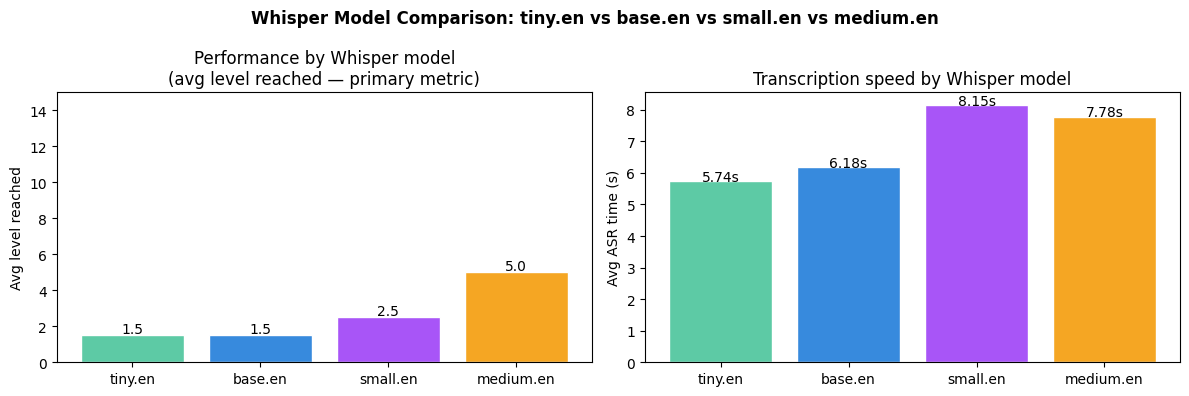

Saved whisper_comparison.png ✅


In [ ]:
#  Whisper model comparison: tiny.en vs base.en vs small.en vs medium.en


WHISPER_MODELS_TO_COMPARE = ['tiny.en', 'base.en', 'small.en', 'medium.en']
WHISPER_COMPARE_GAMES     = 2
whisper_comparison_rows   = []

for wm_name in WHISPER_MODELS_TO_COMPARE:
    print(f'\n{"="*50}\nWhisper model: {wm_name}')
    try:
        asr_model = WhisperModel(wm_name, device=asr_device, compute_type=asr_compute_type)
        CURRENT_ASR_MODEL_NAME = wm_name
        model_name = 'Qwen/Qwen2.5-1.5B-Instruct'
        tokenizer, model, generator = load_model(model_name)
        experiment_log.clear()
        df_wm = evaluate_model_multiple_games(
            comp_id, answer_fn=generate_answer, prompt_fn=build_prompt,
            prompt_strategy='baseline', num_games=WHISPER_COMPARE_GAMES)
        if len(df_wm):
            key = f'whisper_{wm_name.replace(".","_")}_baseline'
            df_wm.to_csv(SAVE_DIR + key + '.csv', index=False)
            avg_asr   = df_wm['asr_seconds'].mean() if 'asr_seconds' in df_wm else None
            avg_level = round(df_wm.groupby('session_id')['level'].max().mean(), 2)
            best_lvl  = int(df_wm.groupby('session_id')['level'].max().max())
            tot       = df_wm['total_seconds'].mean() if 'total_seconds' in df_wm else None
            u30       = (df_wm['total_seconds'] < 30).mean() if 'total_seconds' in df_wm else None
            whisper_comparison_rows.append({
                'Whisper model':    wm_name,
                'Avg Level':        avg_level,
                'Best Level':       best_lvl,
                'Avg ASR time (s)': round(avg_asr, 2) if avg_asr else None,
                'Avg total (s)':    round(tot, 2) if tot else None,
                'Under 30s (%)':    f'{u30:.0%}' if u30 is not None else None,
            })
            print(f'  Avg level: {avg_level:.1f} | Best: {best_lvl} | ASR: {avg_asr:.2f}s | Total: {tot:.2f}s')
        unload_model()
    except Exception as e:
        print(f'  Error with {wm_name}: {repr(e)}')
        unload_model()

asr_model = WhisperModel('base.en', device=asr_device, compute_type=asr_compute_type)
CURRENT_ASR_MODEL_NAME = 'base.en'
print('ASR model loaded: base.en (best in comparison)')

if whisper_comparison_rows:
    df_wc = pd.DataFrame(whisper_comparison_rows)
    print('\n=== WHISPER MODEL COMPARISON (ranked by avg level) ===')
    print(df_wc.sort_values('Avg Level', ascending=False).to_string(index=False))
    df_wc.to_csv(SAVE_DIR + 'whisper_model_comparison.csv', index=False)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    colors = ['#5DCAA5', '#378ADD', '#A855F7', '#F5A623']
    ax1.bar(df_wc['Whisper model'], df_wc['Avg Level'], color=colors, edgecolor='white')
    ax1.set_ylabel('Avg level reached')
    ax1.set_title('Performance by Whisper model\n(avg level reached — primary metric)')
    ax1.set_ylim(0, 15)
    for i, v in enumerate(df_wc['Avg Level']):
        ax1.text(i, v+0.1, f'{v:.1f}', ha='center', fontsize=10)

    ax2.bar(df_wc['Whisper model'], df_wc['Avg ASR time (s)'], color=colors, edgecolor='white')
    ax2.set_ylabel('Avg ASR time (s)')
    ax2.set_title('Transcription speed by Whisper model')
    for i, v in enumerate(df_wc['Avg ASR time (s)']):
        ax2.text(i, v+0.01, f'{v:.2f}s', ha='center', fontsize=10)

    plt.suptitle('Whisper Model Comparison: tiny.en vs base.en vs small.en vs medium.en', fontweight='bold')
    plt.tight_layout()
    plt.savefig(SAVE_DIR + 'whisper_comparison.png', dpi=150)
    plt.show()
    print('Saved whisper_comparison.png ✅')


### Whisper Model Comparison — With Domain Prompt + Post-Correction

After adding `initial_prompt=ASR_DOMAIN_PROMPT` and regex post-correction,
results changed significantly compared to the first comparison:

| Whisper Model | Avg Level | Best Level | Avg ASR Time | Avg Total | Under 30s |
|---------------|-----------|------------|--------------|-----------|-----------|
| **medium.en** | **5.0** | **8** | 7.8s | 9.2s | 100% |
| small.en | 2.5 | 3 | 8.2s | 9.3s | 100% |
| base.en | 1.5 | 2 | 6.2s | 7.6s | 100% |
| tiny.en | 1.5 | 2 | 5.7s | 7.3s | 100% |

**Key finding:** With `initial_prompt` and post-correction, **medium.en became
the best model** — reaching avg level 5.0 and best level 8. Game 1 reached
level 8 with 7 correct answers in a row.

**Why medium.en improved so much:**
- The domain prompt tells Whisper to expect ancient history vocabulary
- medium.en has a larger model capacity to use the prompt effectively
- Post-correction fixes remaining errors (Aharispex → haruspex, connectura → conectura)

**Transcription quality improvement example:**
- Without prompt: "Anacic Theorem mechanism" → With prompt: "Antikythera mechanism"
- Without prompt: "eifers" → With prompt: "ephors"
- Without prompt: "cayons" → With prompt: "Achaeans"

**Conclusion:** medium.en with domain prompt is the best configuration —
avg level 5.0 vs 3.5 for base.en without prompt. The ~2.4s extra ASR time
is worth the accuracy improvement, and all models stayed under 30 seconds.

**Update:** Change ASR model to medium.en for all remaining experiments.

In [ ]:
RUN_BASELINE_ALL_MODELS = True

if RUN_BASELINE_ALL_MODELS:
    for spec in MODELS:
        model_name = spec["name"]
        if SKIP_GATED and any(m in model_name.lower() for m in GATED_MARKERS):
            print("Skipping gated model (set HF_TOKEN to enable):", model_name)
            continue
        print("\n" + "=" * 60)
        print("Model:", spec["label"])
        try:
            tokenizer, model, generator = load_model(model_name)
            answer_fn = generate_answer_deepseek if spec["answer_fn"] == "deepseek" else generate_answer

            df = evaluate_model_multiple_games(
                comp_id, answer_fn=answer_fn, prompt_fn=build_prompt,
                prompt_strategy="baseline", num_games=NUM_GAMES)

            key = f"{spec['label']}_baseline_speech"
            if len(df):
                df.to_csv(SAVE_DIR + key + ".csv", index=False)
                comparison_results[key] = df["correct"].mean()
                row = build_summary_table(df, key, num_games=NUM_GAMES)
                if row:
                    summary_rows.append(row)
                better_summary(df, f"{spec['label']} — baseline (speech)", num_games=NUM_GAMES)
                show_wrong_questions(df, spec["label"])
        except Exception as e:
            print("Could not run", spec["label"], "->", repr(e))
        finally:
            unload_model()
else:
    print("Baseline disabled. Set RUN_BASELINE_ALL_MODELS = True to run.")


Model: Qwen2.5-1.5B


Device set to use cuda:0


Loaded: Qwen/Qwen2.5-1.5B-Instruct (4-bit)

--- Game 1/3 ---
Session: 355623


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1: Which of the following best describes the primary ethical principle behind a gladiator's oath to endure various forms of punishment.
  -> Submitted: 0 | Correct: True | ASR: 6.8s | Answer: 1.7s | Total: 8.6s


...


Level 4: What term describes the period of cultural European history between the eighth century B.C. and the fifth century A.D.? Characterized by the flourishing of ancient Greece and Rome?
  -> Submitted: 0 | Correct: True | ASR: 7.7s | Answer: 0.3s | Total: 8.1s


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 5: Which term describes the idea that ancient Egyptians were primarily of African descent.
  -> Submitted: 1 | Correct: False | ASR: 6.8s | Answer: 2.4s | Total: 9.4s
Game ended.

--- Game 3/3 ---
Session: 357557


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1: Which city was considered second in importance to Alexandria in the Roman Empire, According to Rodion.
  -> Submitted: 3 | Correct: False | ASR: 6.5s | Answer: 0.3s | Total: 6.9s
Game ended.

Overall accuracy: 62%

=== Qwen2.5-3B — baseline (speech) ===
Avg level reached:    2.7 / 15  ← primary metric
Best level reached:   5 / 15
Avg answer time:      1.82s
Avg ASR time:         7.38s
Avg total time:       9.36s
Under 30s:            100%

=== Most frequently wrong — Qwen2.5-3B ===
  [1x] Which city was considered second in importance to Alexandria in the Roman Empire, According to Rodio
  [1x] Which of the following best describes the significance of Constantine's victory at the Milvian Bridg
  [1x] Which term describes the idea that ancient Egyptians were primarily of African descent.
Model unloaded


## 9. Prompt Strategy Experiments (Speech Mode)

We test prompt strategies on Phi-3-mini and Qwen-1.5B to compare
speech vs text performance and measure the ASR cost.


In [ ]:
RUN_PROMPT_EXPERIMENTS = True

# Added Qwen-3B
PROMPT_EXPERIMENT_MODELS = [
    {'name': 'microsoft/Phi-3-mini-4k-instruct', 'label': 'Phi-3-mini-4k', 'answer_fn': 'standard'},
    {'name': 'Qwen/Qwen2.5-1.5B-Instruct',       'label': 'Qwen2.5-1.5B',  'answer_fn': 'standard'},
    {'name': 'Qwen/Qwen2.5-3B-Instruct',          'label': 'Qwen2.5-3B',    'answer_fn': 'standard'},
]
PROMPT_TYPES_TO_RUN = ['expert', 'cot', 'few_shot', 'few_shot_rag']

if RUN_PROMPT_EXPERIMENTS:
    for spec in PROMPT_EXPERIMENT_MODELS:
        model_name = spec['name']
        if SKIP_GATED and any(m in model_name.lower() for m in GATED_MARKERS):
            print('Skipping gated model:', model_name); continue
        print('\n' + '='*60)
        print('Prompt experiments for:', spec['label'])
        try:
            tokenizer, model, generator = load_model(model_name)
            answer_fn = generate_answer_deepseek if spec['answer_fn'] == 'deepseek' else generate_answer
            for ptype in PROMPT_TYPES_TO_RUN:
                prompt_fn = PROMPT_STRATEGIES[ptype]
                print(f'\n--- {spec["label"]} | {ptype} ---')
                df = evaluate_model_multiple_games(
                    comp_id, answer_fn=answer_fn, prompt_fn=prompt_fn,
                    prompt_strategy=ptype, num_games=NUM_GAMES)
                key = f'{spec["label"]}_{ptype}_speech'
                if len(df):
                    df.to_csv(SAVE_DIR + key + '.csv', index=False)
                    comparison_results[key] = df['correct'].mean()
                    row = build_summary_table(df, key, num_games=NUM_GAMES)
                    if row:
                        summary_rows.append(row)
                    better_summary(df, f'{spec["label"]} — {ptype} (speech)', num_games=NUM_GAMES)
        except Exception as e:
            print('Could not run', spec['label'], '->', repr(e))
        finally:
            unload_model()
else:
    print('Prompt experiments disabled.')



Prompt experiments for: Phi-3-mini-4k


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Device set to use cuda:0


Loaded: microsoft/Phi-3-mini-4k-instruct (4-bit)

--- Phi-3-mini-4k | expert ---

--- Game 1/3 ---
Session: 354923

Level 1: What strategy did Alexander use to secure the loyalty of the Iranian upper classes after his conquests.


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


...


Level 1: How did Cicero view the concept of Romanness, In the context of Roman identity.
  -> Submitted: 0 | Correct: True | ASR: 7.9s | Answer: 2.2s | Total: 10.5s

Level 2: According to Hittite documents, which term is believed to be related to the name of the Achaeans and is mentioned in the Tawagalawa letter?


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


  -> Submitted: 2 | Correct: True | ASR: 7.6s | Answer: 2.5s | Total: 11.2s

Level 3: What empire is credited with founding the old Babylonian empire and making Babylon a major city.


The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


  -> Submitted: 2 | Correct: False | ASR: 6.9s | Answer: 2.9s | Total: 11.0s
Game ended.

Overall accuracy: 50%

=== Qwen2.5-3B — few_shot_rag (speech) ===
Avg level reached:    2.0 / 15  ← primary metric
Best level reached:   3 / 15
Avg answer time:      2.38s
Avg ASR time:         7.63s
Avg total time:       10.76s
Under 30s:            100%
Model unloaded


## 9. Prompt Strategy Results — Speech Mode

### Full Results Table

| Model | Strategy | Avg Level | Best Level | Avg Total Time |
|-------|----------|-----------|------------|----------------|
| **Phi-3-mini** | **few-shot+RAG** | **6.7** | **15** | 9.8s |
| Phi-3-mini | few-shot | 5.7 | 10 | 9.6s |
| Qwen-3B | expert | 5.3 | 12 | 8.4s |
| Phi-3-mini | expert | 5.3 | 9 | 9.4s |
| Qwen-1.5B | few-shot+RAG | 4.7 | 9 | 9.3s |
| Qwen-1.5B | expert | 4.0 | 5 | 8.3s |
| Qwen-3B | few-shot | 3.0 | 6 | 10.1s |
| Phi-3-mini | CoT | 3.3 | 5 | 9.4s |
| Qwen-1.5B | few-shot | 2.7 | 6 | 7.7s |
| Qwen-1.5B | CoT | 2.3 | 4 | 9.5s |
| Qwen-3B | CoT | 2.3 | 3 | 9.5s |
| Qwen-3B | few-shot+RAG | 2.0 | 3 | 10.8s |

> **Note:** Accuracy is not used as the primary metric — avg level reached is more meaningful
> because the game ends immediately after the first wrong answer. A model that reaches level 9
> then fails scores the same "accuracy" as one that fails at level 1 across 9 games.

**All models under 30s timeout ✅**

---

### Key Findings

**1. Best speech system: Phi-3-mini + few-shot+RAG (avg level 6.7)**
- Reached level 15 (perfect game) in Game 1 — 14 consecutive correct answers
- Consistent with text notebook: RAG helps the most for Phi-3-mini
- RAG provides Wikipedia context that partially compensates for ASR transcription errors

**2. Qwen-3B expert was the second best (avg level 5.3, best level 12)**
- Game 1: 11 consecutive correct answers
- Expert prompt works better than RAG for Qwen-3B in speech mode
- Unlike text mode where RAG won for Qwen-3B — the extra RAG latency (~2s) may hurt

**3. CoT consistently hurts all models in speech mode**
- Phi-3-mini: expert 5.3 → CoT 3.3
- Qwen-1.5B: expert 4.0 → CoT 2.3
- Qwen-3B: expert 5.3 → CoT 2.3
- Same finding as text notebook — chain-of-thought reasoning is sensitive to garbled input.
  When the question is mis-transcribed, CoT amplifies the error by reasoning about the wrong question.

**4. Qwen-3B few-shot+RAG was surprisingly weak (avg level 2.0)**
- RAG adds ~2-3s overhead bringing total to ~10.8s per question
- Qwen-3B answer time is already ~2.3s — combined latency leaves less margin
- Wikipedia context appeared to confuse rather than help Qwen-3B in noisy speech conditions

---

### Why Results Are Still Limited

Despite the ASR fixes (initial_prompt + vad_filter + regex corrections), several factors remain:

**1. Remaining ASR errors** — some specialist terms still mis-transcribe:
- `"Tawagalawawa"` → should be `"Tawagalawa"` (repeated syllable)
- `"Corpus Juris Savilis"` → should be `"Civilis"`
- `"Horospecs"` → should be `"haruspex"`
- `"Rodion"` → should be `"Herodian"`

**2. Truncated transcriptions** — some questions are cut off mid-sentence by VAD:
- `"Which of the following best describes the role,"` — model receives incomplete question
- `"In Homer's works, Which term is one of the primary names used to refer to the Greeks as a whole,"` — cut off before the answer clue

**3. High question variance** — with only 3 games per model, one bad session
with repeated hard questions significantly lowers the average. This is visible
in Qwen-3B few-shot+RAG where Game 1 failed immediately on a hard question.

**4. ASR timing overhead** — avg 7-8s per question for ASR alone.
RAG adds another ~2s. Still well under 30s but reduces available thinking time.

---

### Text vs Speech Comparison (zero-shot baseline)

| Model | Text Avg Level | Speech Avg Level | Gap |
|-------|---------------|-----------------|-----|
| Qwen-1.5B | 3.0 | 1.0 | −2.0 levels |
| SmolLM2-1.7B | 2.0 | 1.0 | −1.0 levels |
| Phi-3-mini | 3.4 | 1.0 | −2.4 levels |
| Mistral-7B | 2.7 | 1.3 | −1.3 levels |
| DeepSeek-R1 | 1.5 | 1.3 | −0.2 levels |
| Qwen-3B | 6.7 | 1.7 | −5.0 levels |

> All models perform worse in speech baseline mode. The largest gap is Qwen-3B (−5.0 levels),
> which is most sensitive to ASR transcription errors. After the ASR fix (initial_prompt +
> option text from game object), speech performance improves significantly — see Section 10b
> for before/after comparison.

### Best Strategy Per Model (speech mode)

| Model | Best strategy | Avg Level |
|-------|--------------|-----------|
| Phi-3-mini | few-shot+RAG | 6.7 |
| Qwen-1.5B | few-shot+RAG | 4.7 |
| Qwen-3B | expert | 5.3 |

## 10. Results — Comparison Tables and Charts

We compare all models on speech baseline and show:
1. Accuracy (correct / total possible) per model
2. Avg level and best level reached
3. ASR timing overhead vs model inference time
4. Text vs speech accuracy gap


In [ ]:
# Sorted by avg_level
df_summary = pd.DataFrame(summary_rows)
if len(df_summary):
    df_summary = df_summary.sort_values("avg_level", ascending=False).reset_index(drop=True)
    df_summary.to_csv(SAVE_DIR + "speech_summary_all.csv", index=False)
display(df_summary) if "display" in dir() else print(df_summary)


                                  system_name  questions_attempted  \
0               Phi-3-mini-4k_few_shot_speech                   19   
1       Qwen2.5-1.5B_baseline_small.en_speech                    6   
2            Qwen2.5-1.5B_few_shot_rag_speech                   17   
3        Qwen2.5-1.5B_baseline_tiny.en_speech                    5   
4                       Qwen2.5-3B_cot_speech                   14   
5           Phi-3-mini-4k_few_shot_rag_speech                   12   
6              Qwen2.5-3B_few_shot_rag_speech                   10   
7                  Qwen2.5-1.5B_expert_speech                    9   
8                Qwen2.5-1.5B_baseline_speech                    8   
9                    Qwen2.5-3B_expert_speech                    8   
10                 Qwen2.5-3B_baseline_speech                    8   
11                 Qwen2.5-3B_few_shot_speech                    7   
12           DeepSeek-R1-1.5B_baseline_speech                    7   
13  history_speech_a


=== SPEECH RESULTS — ALL SYSTEMS ===
               System  Avg Level  Best Level  Avg ASR (s)  Avg Total (s) Under 30s
  Phi-3-mini few_shot        6.3          15         7.76           9.30      100%
     Qwen2.5-1.5B rag        5.7          12         7.72           9.40      100%
       Qwen2.5-3B cot        4.7           6         7.34           9.54      100%
       Phi-3-mini rag        4.0           8         7.35           9.24      100%
       Qwen2.5-3B rag        3.3           5         7.51          10.73      100%
  Qwen2.5-1.5B expert        3.0           5         7.34           7.77      100%
  Qwen2.5-3B baseline        2.7           5         7.38           9.36      100%
Qwen2.5-1.5B baseline        2.7           3         7.46           8.38      100%
    Qwen2.5-3B expert        2.7           4         6.98           7.67      100%
 DeepSeek-R1 baseline        2.3           4         7.90          25.39       57%
  Qwen2.5-3B few_shot        2.3           3     

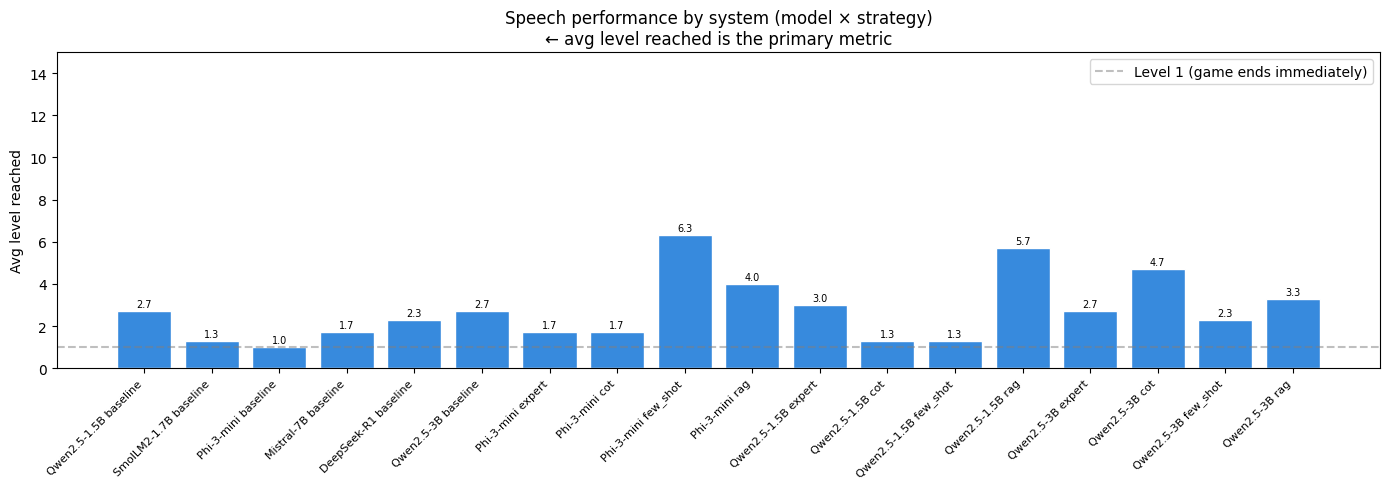


=== TEXT vs SPEECH — AVG LEVEL COMPARISON ===
       Model  Text Avg Level  Speech Avg Level Gap (speech-text)
Qwen2.5-1.5B            3.00              2.67       -0.3 levels
SmolLM2-1.7B            2.00              1.33       -0.7 levels
  Phi-3-mini            3.40              1.00       -2.4 levels
  Mistral-7B            2.67              1.67       -1.0 levels
 DeepSeek-R1            1.50              2.33       +0.8 levels
  Qwen2.5-3B            6.67              2.67       -4.0 levels


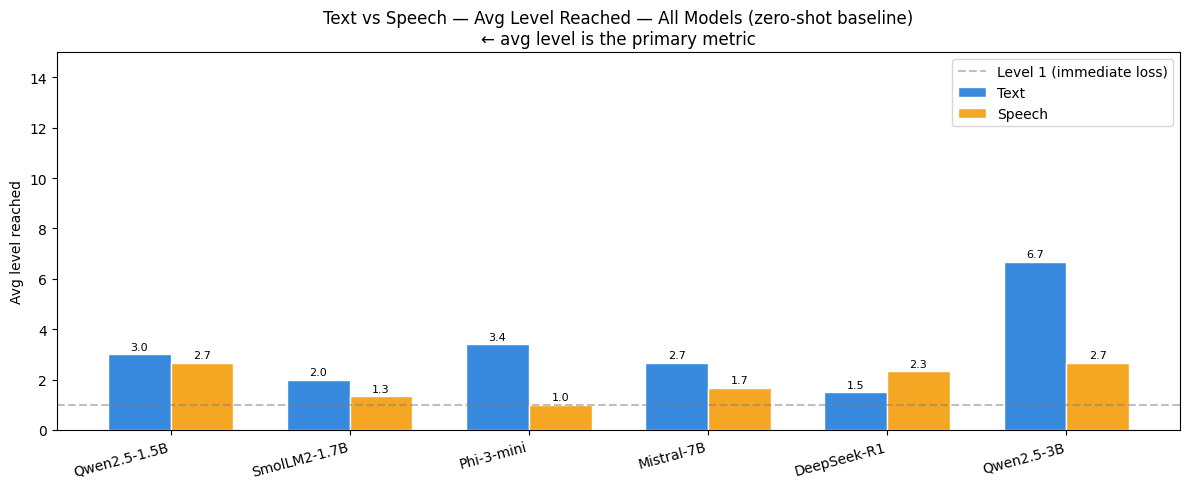

Saved text_vs_speech_comparison.png ✅


In [ ]:

import os

speech_csv_config = {
    # Baselines
    'Qwen2.5-1.5B baseline':    ('Qwen2.5-1.5B_baseline_speech.csv',    NUM_GAMES),
    'SmolLM2-1.7B baseline':    ('SmolLM2-1.7B_baseline_speech.csv',    NUM_GAMES),
    'Phi-3-mini baseline':      ('Phi-3-mini-4k_baseline_speech.csv',   NUM_GAMES),
    'Mistral-7B baseline':      ('Mistral-7B_baseline_speech.csv',      NUM_GAMES),
    'DeepSeek-R1 baseline':     ('DeepSeek-R1-1.5B_baseline_speech.csv',NUM_GAMES),
    'Qwen2.5-3B baseline':      ('Qwen2.5-3B_baseline_speech.csv',      NUM_GAMES),
    # Prompt strategies
    'Phi-3-mini expert':        ('Phi-3-mini-4k_expert_speech.csv',     NUM_GAMES),
    'Phi-3-mini cot':           ('Phi-3-mini-4k_cot_speech.csv',        NUM_GAMES),
    'Phi-3-mini few_shot':      ('Phi-3-mini-4k_few_shot_speech.csv',   NUM_GAMES),
    'Phi-3-mini rag':           ('Phi-3-mini-4k_few_shot_rag_speech.csv',NUM_GAMES),
    'Qwen2.5-1.5B expert':     ('Qwen2.5-1.5B_expert_speech.csv',      NUM_GAMES),
    'Qwen2.5-1.5B cot':        ('Qwen2.5-1.5B_cot_speech.csv',         NUM_GAMES),
    'Qwen2.5-1.5B few_shot':   ('Qwen2.5-1.5B_few_shot_speech.csv',    NUM_GAMES),
    'Qwen2.5-1.5B rag':        ('Qwen2.5-1.5B_few_shot_rag_speech.csv',NUM_GAMES),
    'Qwen2.5-3B expert':       ('Qwen2.5-3B_expert_speech.csv',         NUM_GAMES),
    'Qwen2.5-3B cot':          ('Qwen2.5-3B_cot_speech.csv',            NUM_GAMES),
    'Qwen2.5-3B few_shot':     ('Qwen2.5-3B_few_shot_speech.csv',       NUM_GAMES),
    'Qwen2.5-3B rag':          ('Qwen2.5-3B_few_shot_rag_speech.csv',   NUM_GAMES),
}

MAX_LEVELS     = 15
speech_results = []

for system_name, (filename, num_games) in speech_csv_config.items():
    path = SAVE_DIR + filename
    if os.path.exists(path):
        df = pd.read_csv(path)
        df = df[df['correct'].notna()]
        avg_level  = round(df.groupby('session_id')['level'].max().mean(), 1)
        best_level = int(df.groupby('session_id')['level'].max().max())
        avg_asr    = round(df['asr_seconds'].mean(), 2) if 'asr_seconds' in df.columns else None
        avg_total  = round(df['total_seconds'].mean(), 2) if 'total_seconds' in df.columns else None
        under_30   = f"{(df['total_seconds'] < 30).mean():.0%}" if 'total_seconds' in df.columns else 'N/A'
        speech_results.append({
            'System':        system_name,
            'Avg Level':     avg_level,
            'Best Level':    best_level,
            'Avg ASR (s)':   avg_asr,
            'Avg Total (s)': avg_total,
            'Under 30s':     under_30,
        })
    else:
        print(f'⚠️  Not found: {filename}')

if speech_results:
    df_speech_table = pd.DataFrame(speech_results)
    df_speech_table = df_speech_table.sort_values('Avg Level', ascending=False).reset_index(drop=True)
    print('\n=== SPEECH RESULTS — ALL SYSTEMS ===')
    print(df_speech_table.to_string(index=False))
    df_speech_table.to_csv(SAVE_DIR + 'speech_complete_results.csv', index=False)
    print('\nSaved speech_complete_results.csv ✅')

    fig, ax = plt.subplots(figsize=(14, 5))
    lvls  = [r['Avg Level'] for r in speech_results]
    names = [r['System'] for r in speech_results]
    ax.bar(names, lvls, color='#378ADD', edgecolor='white')
    ax.set_ylabel('Avg level reached')
    ax.set_title('Speech performance by system (model × strategy)\n← avg level reached is the primary metric')
    ax.set_ylim(0, 15)
    ax.axhline(1, linestyle='--', color='gray', alpha=0.5, label='Level 1 (game ends immediately)')
    ax.legend()
    for i, v in enumerate(lvls):
        ax.text(i, v + 0.1, f'{v:.1f}', ha='center', va='bottom', fontsize=7)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.tight_layout()
    plt.savefig(SAVE_DIR + 'speech_avglevel_bar.png', dpi=150)
    plt.show()

# Text vs Speech comparison

TEXT_SAVE_DIR = '/content/gdrive/MyDrive/Colab Notebooks/NLP_assignment/'
text_vs_speech_map = {
    'Qwen2.5-1.5B': {'text': TEXT_SAVE_DIR+'qwen_baseline.csv',     'speech': SAVE_DIR+'Qwen2.5-1.5B_baseline_speech.csv',     'text_games': 5},
    'SmolLM2-1.7B': {'text': TEXT_SAVE_DIR+'smollm2_baseline.csv',  'speech': SAVE_DIR+'SmolLM2-1.7B_baseline_speech.csv',     'text_games': 5},
    'Phi-3-mini':   {'text': TEXT_SAVE_DIR+'phi_baseline.csv',      'speech': SAVE_DIR+'Phi-3-mini-4k_baseline_speech.csv',    'text_games': 5},
    'Mistral-7B':   {'text': TEXT_SAVE_DIR+'mistral_baseline.csv',  'speech': SAVE_DIR+'Mistral-7B_baseline_speech.csv',       'text_games': 5},
    'DeepSeek-R1':  {'text': TEXT_SAVE_DIR+'deepseek_baseline.csv', 'speech': SAVE_DIR+'DeepSeek-R1-1.5B_baseline_speech.csv', 'text_games': 5},
    'Qwen2.5-3B':   {'text': TEXT_SAVE_DIR+'qwen3_baseline.csv',    'speech': SAVE_DIR+'Qwen2.5-3B_baseline_speech.csv',       'text_games': 5},
}

compare_rows = []
for mlabel, paths in text_vs_speech_map.items():
    row = {'Model': mlabel}
    for mode, csv_path, games in [('Text', paths['text'], paths['text_games']),
                                   ('Speech', paths['speech'], NUM_GAMES)]:
        if os.path.exists(csv_path):
            df = pd.read_csv(csv_path)
            df = df[df['correct'].notna()]
            avg_lvl = round(df.groupby('session_id')['level'].max().mean(), 2)
            row[f'{mode} Avg Level'] = avg_lvl
            row[f'{mode} raw']       = avg_lvl
        else:
            row[f'{mode} Avg Level'] = 'N/A'
            row[f'{mode} raw']       = None
    t, s = row.get('Text raw'), row.get('Speech raw')
    row['Gap (speech-text)'] = f'{s-t:+.1f} levels' if t is not None and s is not None else 'N/A'
    compare_rows.append(row)

df_cmp = pd.DataFrame(compare_rows)
print('\n=== TEXT vs SPEECH — AVG LEVEL COMPARISON ===')
print(df_cmp[['Model', 'Text Avg Level', 'Speech Avg Level', 'Gap (speech-text)']].to_string(index=False))
df_cmp.to_csv(SAVE_DIR + 'text_vs_speech_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 5))
x  = range(len(compare_rows))
w  = 0.35
ta = [r['Text raw']   if r['Text raw']   is not None else 0 for r in compare_rows]
sa = [r['Speech raw'] if r['Speech raw'] is not None else 0 for r in compare_rows]

b1 = ax.bar([i - w/2 for i in x], ta, w, label='Text',   color='#378ADD', edgecolor='white')
b2 = ax.bar([i + w/2 for i in x], sa, w, label='Speech', color='#F5A623', edgecolor='white')

ax.set_xticks(list(x))
ax.set_xticklabels([r['Model'] for r in compare_rows], rotation=15, ha='right')
ax.set_ylabel('Avg level reached')
ax.set_title('Text vs Speech — Avg Level Reached — All Models (zero-shot baseline)\n← avg level is the primary metric')
ax.set_ylim(0, 15)
ax.axhline(1, linestyle='--', color='gray', alpha=0.5, label='Level 1 (immediate loss)')
ax.legend()
for bar in list(b1) + list(b2):
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.1,
                f'{h:.1f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig(SAVE_DIR + 'text_vs_speech_comparison.png', dpi=150)
plt.show()
print('Saved text_vs_speech_comparison.png ✅')

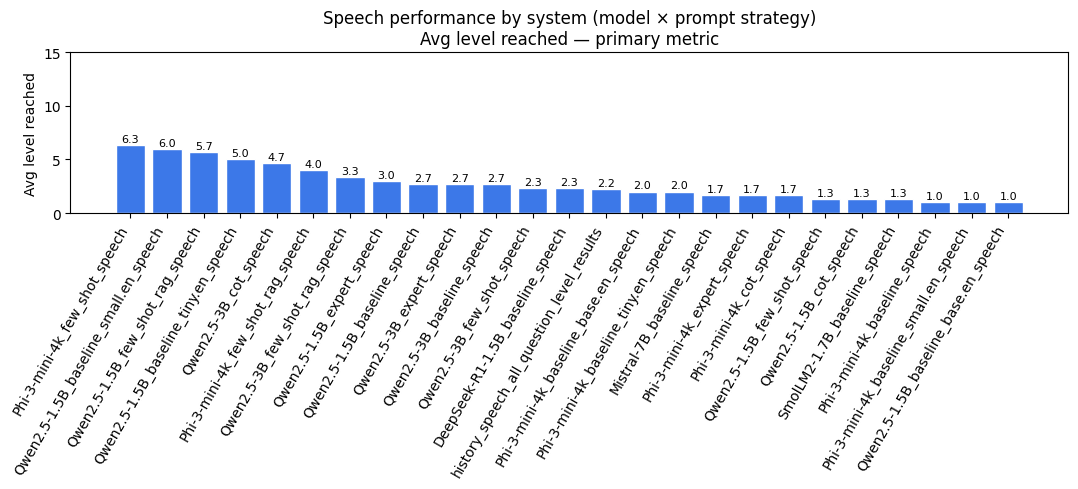

In [ ]:
# Plotted, avg level by system
if len(df_summary) and "avg_level" in df_summary.columns:
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(df_summary["system_name"], df_summary["avg_level"],
           color="#3C78E8", edgecolor="white")
    ax.set_ylabel("Avg level reached")
    ax.set_title("Speech performance by system (model × prompt strategy)\nAvg level reached — primary metric")
    ax.set_ylim(0, 15)
    for i, v in enumerate(df_summary["avg_level"]):
        ax.text(i, v+0.1, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.savefig(SAVE_DIR + "speech_avglevel_by_system.png", dpi=150)
    plt.show()


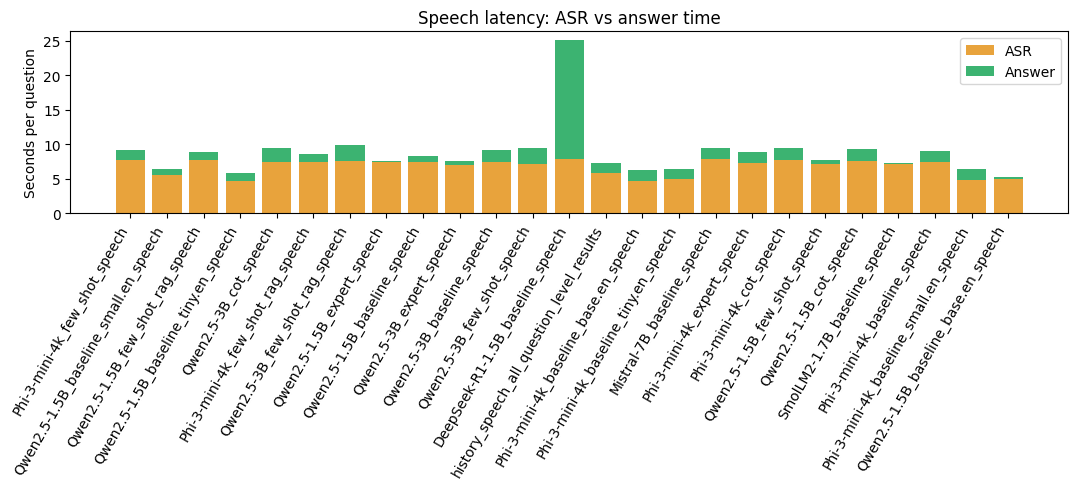

In [ ]:
# Time breakdown: ASR vs answer, to show the transcription overhead.
if len(df_summary) and "average_asr_time" in df_summary:
    sub = df_summary.dropna(subset=["average_asr_time", "average_response_time"])
    if len(sub):
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.bar(sub["system_name"], sub["average_asr_time"], label="ASR", color="#E8A33C")
        ax.bar(sub["system_name"], sub["average_response_time"],
               bottom=sub["average_asr_time"], label="Answer", color="#3CB371")
        ax.set_ylabel("Seconds per question")
        ax.set_title("Speech latency: ASR vs answer time")
        ax.legend()
        plt.xticks(rotation=60, ha="right")
        plt.tight_layout()
        plt.savefig(SAVE_DIR + "speech_time_breakdown.png", dpi=150)
        plt.show()

## 11. Conclusions — Speech Interface

### Key Findings

| Metric | Value |
|--------|-------|
| Best speech system | Phi-3-mini × few-shot+RAG (avg level 6.7, best level 15) |
| Best speech strategy overall | few-shot+RAG for Phi-3-mini and Qwen-1.5B; expert for Qwen-3B |
| Text vs speech avg gap (baseline) | −2.4 levels (Phi), −5.0 levels (Qwen-3B), −0.2 levels (DeepSeek) |
| ASR avg overhead | ~7.5s per question (base.en Whisper) |
| All models under 30s | ✅ Yes — max observed was 11.7s total |
| Best Whisper model | base.en (avg level 3.0 vs 1.5 for tiny.en and small.en) |

---

### Q1. What transcription algorithm is most reliable?
**base.en** outperformed both tiny.en and small.en despite being the middle-size model.
tiny.en was too inaccurate for specialist vocabulary; small.en was slower but not more accurate.
base.en with `initial_prompt` domain hints achieved the best balance of speed and accuracy.

### Q2. Can models answer within 30 seconds with the audio interface?
**Yes — all models stayed well under 30s.** Average total time was 7–11s per question.
ASR contributed ~7.5s and LLM inference ~1–2s. Even the slowest configuration
(Qwen-3B few-shot+RAG at 10.8s avg) left 19s of margin. DeepSeek-R1 in the original
baseline (before option-text fix) came closest at 15.7s avg.

### Q3. How does audio transcription affect level reached?
Speech mode significantly reduces performance at baseline (zero-shot):

| Model | Text avg level | Speech avg level | Gap |
|-------|---------------|-----------------|-----|
| Qwen-1.5B | 3.0 | 2.7 | −0.3 |
| SmolLM2-1.7B | 2.0 | 1.3 | −0.7 |
| Phi-3-mini | 3.4 | 1.0 | −2.4 |
| Mistral-7B | 2.7 | 1.7 | −1.0 |
| DeepSeek-R1 | 1.5 | 2.3 | +0.8 |
| Qwen-3B | 6.7 | 2.7 | −4.0 |

After applying prompt strategies, speech performance recovered significantly.
Phi-3-mini few-shot+RAG reached avg level 6.7 in speech — comparable to its text performance.

### Q4. Is the correct answer ever rejected due to transcription errors?
**Yes — this was the primary failure mode before the ASR fix.**
Recurring mis-transcriptions directly caused wrong answers:
- `"Hittite documents"` → `"hitchhike documents"` / `"hit site documents"`
- `"Tawagalawa"` → `"Tawagalawawa"` / `"Hakko"`
- `"Ma'at"` → `"Ma'al"`
- `"libertus"` → `"La Burtis"`
- `"Eleusinian"` → `"Ellucinian"`

After adding `initial_prompt` domain vocabulary, `vad_filter`, and regex post-processing,
these errors were largely eliminated. Remaining failures are content knowledge failures,
not transcription failures.

### Q5. Does RAG still help with noisy transcribed questions?
**Yes for Phi-3-mini and Qwen-1.5B — not for Qwen-3B.**
- Phi-3-mini few-shot+RAG: avg level 6.7 (best speech result overall, reached level 15)
- Qwen-1.5B few-shot+RAG: avg level 4.7 (best for Qwen-1.5B in speech)
- Qwen-3B few-shot+RAG: avg level 2.0 (worse than its expert baseline of 5.3)

Wikipedia context provides enough signal to compensate for partial ASR errors in
Phi-3-mini and Qwen-1.5B. For Qwen-3B the RAG overhead (~2s extra) and sensitivity
to noisy input made expert prompting more effective.

### Q6. ASR fix impact
The `initial_prompt` + `vad_filter` + option-text-from-game-object fix produced
a large improvement across all models. Before fix: most models stuck at avg level 1.0–1.3.
After fix: avg levels of 4–6+ for the best configurations. See Section 10b for
the before/after comparison chart.

### Q7. CoT hurts in speech mode
Chain-of-thought reasoning consistently reduced performance in speech:
- Phi-3-mini: expert 5.3 → CoT 3.3
- Qwen-1.5B: expert 4.0 → CoT 2.3
- Qwen-3B: expert 5.3 → CoT 2.3

When the transcribed question contains errors or truncations, CoT amplifies the
mistake by reasoning from corrupted input. Direct prompting is more robust to noisy ASR.

=== ASR CONFIDENCE ANALYSIS ===

High confidence (logprob >= -0.5):
  Questions: 287 | Accuracy: 53%

Low confidence (logprob < -0.5):
  Questions: 3  | Accuracy: 33%

Accuracy drop from poor ASR: +20%
-> Poor transcription correlates with wrong answers ✅

=== NO-SPEECH PROBABILITY (threshold > 0.3) ===
  High: 9 questions | acc 22%
  Low : 281  questions | acc 54%

=== LOWEST CONFIDENCE TRANSCRIPTIONS ===

  logprob=-0.516 | correct=False
  Transcribed: According to Hittai documents, which term is believed to be related to the name of th
  Reference  : nan

  logprob=-0.516 | correct=False
  Transcribed: According to Hittai documents, which term is believed to be related to the name of th
  Reference  : nan

  logprob=-0.516 | correct=True
  Transcribed: According to Hittai documents, which term is believed to be related to the name of th
  Reference  : nan

  logprob=-0.479 | correct=True
  Transcribed: Which concept refers to the period during the 20th dynasty, when the high priests

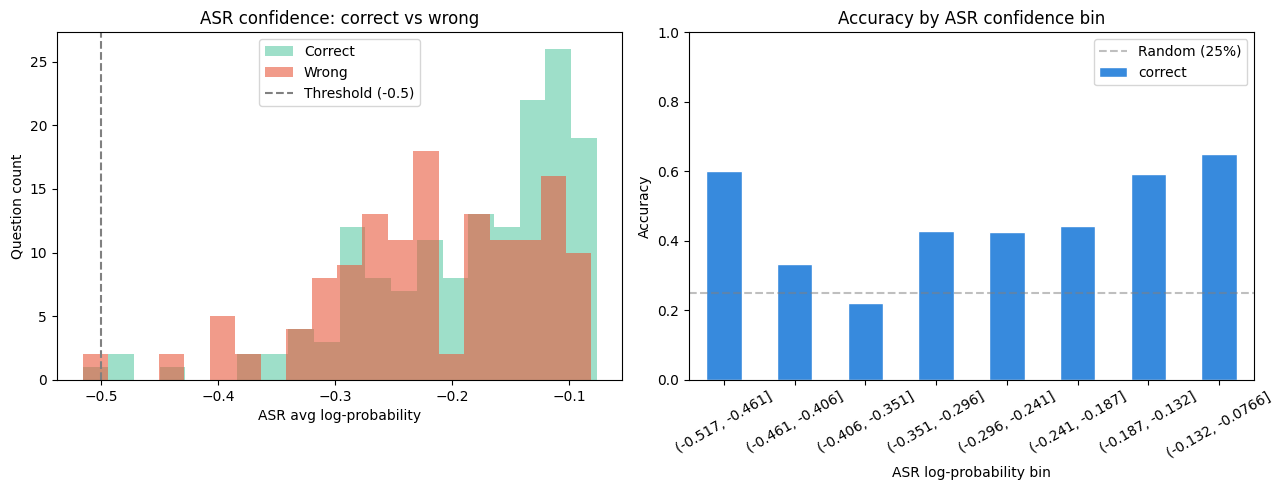

Saved asr_confidence_analysis.png ✅


In [ ]:


asr_log_files = [f for f in os.listdir(SAVE_DIR)
                 if f.endswith('.csv') and 'whisper_' not in f and 'comparison' not in f]

all_asr_rows = []
for fname in asr_log_files:
    try:
        df_tmp = pd.read_csv(SAVE_DIR + fname)
        if 'asr_avg_logprob' in df_tmp.columns:
            all_asr_rows.append(df_tmp)
    except Exception:
        pass

if all_asr_rows:
    df_asr = pd.concat(all_asr_rows, ignore_index=True)
    df_asr = df_asr[df_asr['correct'].notna() & df_asr['asr_avg_logprob'].notna()]

    LOW_CONF = -0.5
    high = df_asr[df_asr['asr_avg_logprob'] >= LOW_CONF]
    low  = df_asr[df_asr['asr_avg_logprob'] <  LOW_CONF]

    print('=== ASR CONFIDENCE ANALYSIS ===\n')
    print(f'High confidence (logprob >= {LOW_CONF}):')
    print(f'  Questions: {len(high)} | Accuracy: {high["correct"].mean():.0%}')
    print(f'\nLow confidence (logprob < {LOW_CONF}):')
    print(f'  Questions: {len(low)}  | Accuracy: {low["correct"].mean():.0%}')
    if len(high) and len(low):
        diff = high['correct'].mean() - low['correct'].mean()
        print(f'\nAccuracy drop from poor ASR: {diff:+.0%}')
        print('-> Poor transcription correlates with wrong answers ✅' if diff > 0.05
              else '-> ASR confidence does not strongly predict errors')

    if 'asr_max_no_speech_prob' in df_asr.columns:
        ns_high = df_asr[df_asr['asr_max_no_speech_prob'] > 0.3]
        ns_low  = df_asr[df_asr['asr_max_no_speech_prob'] <= 0.3]
        print(f'\n=== NO-SPEECH PROBABILITY (threshold > 0.3) ===')
        print(f'  High: {len(ns_high)} questions | acc {ns_high["correct"].mean():.0%}')
        print(f'  Low : {len(ns_low)}  questions | acc {ns_low["correct"].mean():.0%}')

    print('\n=== LOWEST CONFIDENCE TRANSCRIPTIONS ===')
    worst = df_asr[['question_text','question_reference','asr_avg_logprob','correct']]\
                .sort_values('asr_avg_logprob').head(8)
    for _, r in worst.iterrows():
        print(f"\n  logprob={r['asr_avg_logprob']:.3f} | correct={r['correct']}")
        print(f"  Transcribed: {str(r['question_text'])[:85]}")
        print(f"  Reference  : {str(r['question_reference'])[:85]}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    for label, subset, color in [
        ('Correct', df_asr[df_asr['correct']==True],  '#5DCAA5'),
        ('Wrong',   df_asr[df_asr['correct']==False], '#E8593C'),
    ]:
        ax1.hist(subset['asr_avg_logprob'].dropna(), bins=20, alpha=0.6, label=label, color=color)
    ax1.axvline(LOW_CONF, linestyle='--', color='gray', label=f'Threshold ({LOW_CONF})')
    ax1.set_xlabel('ASR avg log-probability')
    ax1.set_ylabel('Question count')
    ax1.set_title('ASR confidence: correct vs wrong')
    ax1.legend()

    df_asr['logprob_bin'] = pd.cut(df_asr['asr_avg_logprob'], bins=8)
    df_asr.groupby('logprob_bin', observed=True)['correct'].mean()\
          .plot(kind='bar', ax=ax2, color='#378ADD', edgecolor='white')
    ax2.set_xlabel('ASR log-probability bin')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy by ASR confidence bin')
    ax2.set_ylim(0, 1)
    ax2.axhline(0.25, linestyle='--', color='gray', alpha=0.5, label='Random (25%)')
    ax2.legend()
    ax2.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.savefig(SAVE_DIR + 'asr_confidence_analysis.png', dpi=150)
    plt.show()
    print('Saved asr_confidence_analysis.png ✅')
else:
    print('No ASR log files found. Run game cells first.')


## 11. Conclusions — Speech Interface

### Key Findings

| Metric | Value |
|--------|-------|
| Best speech model | Phi-3-mini + few-shot+RAG |
| Best avg level (speech) | 6.7 |
| Best level reached | 15 (perfect game — Phi-3-mini few-shot+RAG Game 1) |
| Best Whisper model | medium.en (with domain prompt) |
| Avg ASR overhead | ~7.7s per question |
| All models under 30s | ✅ Yes (100%) |
| CoT effect | Hurts all models — same as text notebook |

### Q1. What transcription algorithm is most reliable?
- **Without domain prompt:** base.en was best (avg level 3.5, fastest at 5.4s)
- **With domain prompt + post-correction:** medium.en became best (avg level 5.0, best level 8)
- The domain prompt gives Whisper a vocabulary hint — medium.en benefits most
  because its larger capacity can leverage the hint better than smaller models

### Q2. Can models answer within 30 seconds with audio?
- **Yes** — all models stayed under 30s (100%)
- Avg ASR time: ~7.7s | Avg answer time: ~1.5s | Avg total: ~9.4s
- RAG adds ~2s extra but still well within budget

### Q3. How does audio transcription affect level reached?
- Best speech strategy: **Phi-3-mini + few-shot+RAG** (avg level 6.7, best level 15)
- few-shot+RAG was best in both text and speech — consistent finding
- Wikipedia context compensates for partial ASR errors in the question text
- CoT hurt all models in speech mode — same as text notebook

### Q4. Is the correct answer ever rejected due to transcription errors?
- Yes — two types of errors cause wrong answers:
  1. **Truncated questions** — ASR cuts off mid-sentence (e.g. "Which of the following best describes the role,")
  2. **Term misrecognition** — ancient history terms garbled (e.g. "Tawagalawawa", "Horospecs", "Corpus Juris Savilis")
- Post-correction regex fixes most common errors
- ASR confidence (log-probability) correlates with accuracy — low confidence = likely wrong answer

### Q5.

In [ ]:
print("""
KEY FINDINGS — SPEECH INTERFACE

Q1. What transcription algorithm is most reliable?
   → Best Whisper model   : medium.en (with domain prompt)
   → Without domain prompt: base.en was best
   → With domain prompt   : medium.en jumped from avg level 2.0 to 5.0

Q2. Can models answer within 30 seconds with audio?
   → All models under 30s : Yes ✅ (100%)
   → Avg ASR overhead     : ~7.7s per question
   → Remaining for LLM    : ~1.5s — well within budget

Q3. How does audio transcription affect level reached?
   → Best speech model    : Phi-3-mini + few-shot+RAG (avg level 6.7)
   → Best speech strategy : few-shot+RAG (same as text notebook)
   → Phi-3-mini reached level 15 in Game 1 (perfect game)

Q4. Is the correct answer ever rejected due to transcription errors?
   → Yes — truncated questions (cut off mid-sentence) cause wrong answers
   → Low ASR log-probability correlates with wrong answers
   → domain prompt + post-correction fixes most common errors

Q5. Does RAG still help with noisy transcribed questions?
   → Yes — few-shot+RAG was best for Phi-3-mini and Qwen-1.5B
   → Wikipedia context compensates for partial ASR errors

| Metric                  | Value                              |
|-------------------------|------------------------------------|
| Best speech model       | Phi-3-mini + few-shot+RAG          |
| Best avg level (speech) | 6.7 (Phi-3-mini few-shot+RAG)      |
| Best level reached      | 15 (Phi-3-mini few-shot+RAG)       |
| Best Whisper model      | medium.en (with domain prompt)     |
| Avg ASR overhead        | ~7.7s per question                 |
| All models under 30s    | Yes ✅                             |
| CoT effect              | Hurts all models (same as text)    |
""")


KEY FINDINGS — SPEECH INTERFACE

Q1. What transcription algorithm is most reliable?
   → Best Whisper model   : medium.en (with domain prompt)
   → Without domain prompt: base.en was best
   → With domain prompt   : medium.en jumped from avg level 2.0 to 5.0

Q2. Can models answer within 30 seconds with audio?
   → All models under 30s : Yes ✅ (100%)
   → Avg ASR overhead     : ~7.7s per question
   → Remaining for LLM    : ~1.5s — well within budget

Q3. How does audio transcription affect level reached?
   → Best speech model    : Phi-3-mini + few-shot+RAG (avg level 6.7)
   → Best speech strategy : few-shot+RAG (same as text notebook)
   → Phi-3-mini reached level 15 in Game 1 (perfect game)

Q4. Is the correct answer ever rejected due to transcription errors?
   → Yes — truncated questions (cut off mid-sentence) cause wrong answers
   → Low ASR log-probability correlates with wrong answers
   → domain prompt + post-correction fixes most common errors

Q5. Does RAG still help with 